# The Impact of Overfitting on Privacy Risks in Neural Networks

## 1. Project Overview

This project investigates the relationship between overfitting and privacy risks in neural networks.

In particular, it examines whether models that overfit more strongly are more vulnerable to Membership Inference Attacks (MIAs), and whether Differential Privacy can reduce these risks while preserving predictive performance.

## 2. Research Questions

1. How does the degree of overfitting affect the vulnerability of neural networks to membership inference attacks?
2. Can Differential Privacy reduce membership inference attack effectiveness?
3. What is the trade-off between predictive performance and privacy protection?

## 3. Experimental Plan

- Dataset: Fashion-MNIST
- Framework: PyTorch
- Baseline: Neural network trained without differential privacy (several training seeds)
- Overfitting analysis: Training and validation performance across training epochs
- Privacy evaluation: Loss-based Membership Inference Attack, implemented in this notebook (Sections 9-11)
- Differential Privacy: DP-SGD with Opacus, implemented in the next notebook (`02_differential_privacy`), which reuses the data split, the baseline checkpoints and exactly the same attack protocol

## 4. Reproducibility

Random seeds, model configurations, the train/validation split indices and evaluation procedures are saved to `results/metrics/` to support reproducible experiments.

In [1]:
import random
import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

from IPython.display import display
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score, roc_curve

SEED = 42


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
METRICS_DIR = RESULTS_DIR / "metrics"
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"

for directory in [DATA_DIR, FIGURES_DIR, METRICS_DIR, CHECKPOINT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Imports completed.")
print("Project directory:", PROJECT_DIR)
print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)
print("Random seed:", SEED)

Imports completed.
Project directory: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks
Python version: 3.11.15
PyTorch version: 2.2.2+cpu
Random seed: 42


## 5. Experimental Configuration

We use Fashion-MNIST, a dataset of grayscale clothing images with ten classes.

The official training set is divided into a training subset (50,000) and a validation subset (10,000). The split is generated once with a fixed seed and its indices are saved, so that the next notebook can reuse exactly the same split.

The validation set is used to study overfitting (training vs. validation performance). The official test set (10,000) is never used for model selection. It is used for two purposes only: the final test accuracy, and as the **non-member** set of the membership inference attack (members = training subset, non-members = test set). The same choice is used for the baseline and for the DP-SGD models.

All model-selection decisions should be based on the training and validation sets rather than repeatedly tuning the model against the test set.

In [2]:
transform = transforms.ToTensor()

full_train_dataset = datasets.FashionMNIST(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root=str(DATA_DIR),
    train=False,
    download=True,
    transform=transform
)

train_size = 50_000
validation_size = 10_000

train_dataset, validation_dataset = random_split(
    full_train_dataset,
    [train_size, validation_size],
    generator=torch.Generator().manual_seed(SEED)
)

split_path = METRICS_DIR / "split_indices.json"
with open(split_path, "w", encoding="utf-8") as file:
    json.dump(
        {
            "seed": SEED,
            "train_indices": list(train_dataset.indices),
            "validation_indices": list(validation_dataset.indices),
        },
        file
    )

assert set(train_dataset.indices).isdisjoint(validation_dataset.indices)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(validation_dataset))
print("Test samples:", len(test_dataset))
print("Number of classes:", len(full_train_dataset.classes))
print("Class names:", full_train_dataset.classes)
print("Split indices saved to:", split_path)

Training samples: 50000
Validation samples: 10000
Test samples: 10000
Number of classes: 10
Class names: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Split indices saved to: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks\results\metrics\split_indices.json


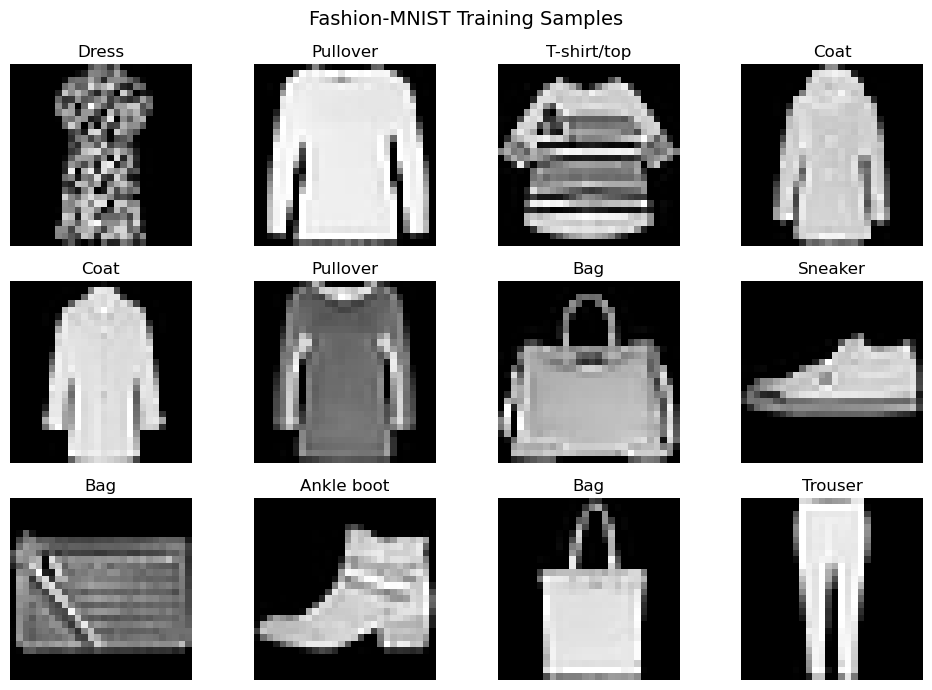

In [3]:
class_names = full_train_dataset.classes

images, labels = next(
    iter(
        DataLoader(
            train_dataset,
            batch_size=12,
            shuffle=True,
            generator=torch.Generator().manual_seed(SEED)
        )
    )
)

fig, axes = plt.subplots(3, 4, figsize=(10, 7))

for index, ax in enumerate(axes.flat):
    ax.imshow(images[index].squeeze(0), cmap="gray")
    ax.set_title(class_names[labels[index].item()])
    ax.axis("off")

fig.suptitle("Fashion-MNIST Training Samples", fontsize=14)
plt.tight_layout()
plt.show()

## 6. Baseline Neural Network

We begin with a simple fully connected neural network.

Each 28 × 28 image is flattened into a 784-dimensional vector. The network contains two hidden layers with ReLU activation functions and an output layer with ten logits, one for each clothing category.

This baseline intentionally uses a simple architecture so that we can study the relationship between generalization behavior and privacy vulnerability before introducing more advanced techniques.

In [4]:
class BaselineMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


architecture_summary = BaselineMLP()

print(architecture_summary)
print(
    "Trainable parameters:",
    sum(parameter.numel() for parameter in architecture_summary.parameters()
        if parameter.requires_grad)
)

BaselineMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 235146


In [5]:
BATCH_SIZE = 128
EPOCHS = 30
LEARNING_RATE = 0.001
CHECKPOINT_EPOCHS = [5, 10, 20, 30]
TRAIN_SEEDS = [42, 43, 44]  

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert max(CHECKPOINT_EPOCHS) <= EPOCHS
assert EPOCHS in CHECKPOINT_EPOCHS, "the final epoch must be a checkpoint (it is the baseline model)"

config = {
    "project": "The Impact of Overfitting on Privacy Risks in Neural Networks",
    "dataset": "Fashion-MNIST",
    "model": "BaselineMLP",
    "seed": SEED,
    "train_seeds": TRAIN_SEEDS,
    "train_size": train_size,
    "validation_size": validation_size,
    "test_size": len(test_dataset),
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "checkpoint_epochs": CHECKPOINT_EPOCHS,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "mia_member_source": "train",
    "mia_nonmember_source": "test",
    "device": str(DEVICE),
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
}

config_path = METRICS_DIR / "baseline_config.json"

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(config, file, indent=4)

print(json.dumps(config, indent=4))
print("\nConfiguration saved to:", config_path)

{
    "project": "The Impact of Overfitting on Privacy Risks in Neural Networks",
    "dataset": "Fashion-MNIST",
    "model": "BaselineMLP",
    "seed": 42,
    "train_seeds": [
        42,
        43,
        44
    ],
    "train_size": 50000,
    "validation_size": 10000,
    "test_size": 10000,
    "batch_size": 128,
    "epochs": 30,
    "checkpoint_epochs": [
        5,
        10,
        20,
        30
    ],
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "mia_member_source": "train",
    "mia_nonmember_source": "test",
    "device": "cpu",
    "python_version": "3.11.15",
    "pytorch_version": "2.2.2+cpu"
}

Configuration saved to: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks\results\metrics\baseline_config.json


## 7. Training the Baseline Model

We train the baseline MLP using the Adam optimizer and cross-entropy loss, for several training seeds.

At the end of each epoch we switch the model to evaluation mode and evaluate it on the **full** training subset and on the validation subset. The training metrics are therefore computed with exactly the same procedure (and the same final weights of that epoch) as the validation metrics and as the membership inference attack, which makes the generalization gap directly comparable to the attack results.

Checkpoints are saved at epochs 5, 10, 20 and 30. The epoch-30 checkpoint of the first seed is the baseline model used in the rest of the project. The official test set is not used here.

In [6]:
train_eval_loader = DataLoader(train_dataset, batch_size=1024, shuffle=False, num_workers=0)
validation_loader = DataLoader(validation_dataset, batch_size=1024, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=False, num_workers=0)


@torch.no_grad()
def evaluate(model, loader, device=DEVICE):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss_sum += nn.functional.cross_entropy(logits, labels, reduction="sum").item()
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return loss_sum / total, correct / total


def train_baseline(train_seed):
    set_seed(train_seed)

    model = BaselineMLP().to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(train_seed)
    )

    rows = []

    for epoch in range(1, EPOCHS + 1):
        model.train()

        for images, labels in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()

        train_loss, train_accuracy = evaluate(model, train_eval_loader)
        val_loss, val_accuracy = evaluate(model, validation_loader)

        rows.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "accuracy_gap": train_accuracy - val_accuracy,
            "loss_gap": val_loss - train_loss,
        })

        if epoch in CHECKPOINT_EPOCHS:
            torch.save(
                {
                    "epoch": epoch,
                    "train_seed": train_seed,
                    "model_state_dict": model.state_dict(),
                    "learning_rate": LEARNING_RATE,
                    "batch_size": BATCH_SIZE,
                },
                CHECKPOINT_DIR / f"baseline_seed{train_seed}_epoch{epoch}.pt"
            )

        print(
            f"[seed {train_seed}] Epoch {epoch:02d}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_accuracy:.4f}"
        )

    return pd.DataFrame(rows)


histories = {}
for train_seed in TRAIN_SEEDS:
    histories[train_seed] = train_baseline(train_seed)

print("\nTraining completed for seeds:", TRAIN_SEEDS)

[seed 42] Epoch 01/30 | Train Loss: 0.4471 | Train Acc: 0.8396 | Val Loss: 0.4749 | Val Acc: 0.8304
[seed 42] Epoch 02/30 | Train Loss: 0.3528 | Train Acc: 0.8725 | Val Loss: 0.3778 | Val Acc: 0.8609
[seed 42] Epoch 03/30 | Train Loss: 0.3265 | Train Acc: 0.8807 | Val Loss: 0.3572 | Val Acc: 0.8704
[seed 42] Epoch 04/30 | Train Loss: 0.2998 | Train Acc: 0.8906 | Val Loss: 0.3352 | Val Acc: 0.8789
[seed 42] Epoch 05/30 | Train Loss: 0.3007 | Train Acc: 0.8872 | Val Loss: 0.3419 | Val Acc: 0.8719
[seed 42] Epoch 06/30 | Train Loss: 0.2994 | Train Acc: 0.8890 | Val Loss: 0.3503 | Val Acc: 0.8713
[seed 42] Epoch 07/30 | Train Loss: 0.2584 | Train Acc: 0.9048 | Val Loss: 0.3163 | Val Acc: 0.8855
[seed 42] Epoch 08/30 | Train Loss: 0.2764 | Train Acc: 0.8939 | Val Loss: 0.3357 | Val Acc: 0.8744
[seed 42] Epoch 09/30 | Train Loss: 0.2360 | Train Acc: 0.9128 | Val Loss: 0.3030 | Val Acc: 0.8911
[seed 42] Epoch 10/30 | Train Loss: 0.2421 | Train Acc: 0.9077 | Val Loss: 0.3282 | Val Acc: 0.8812


In [7]:
PRIMARY_SEED = TRAIN_SEEDS[0]

history_df = histories[PRIMARY_SEED]
all_history_df = pd.concat(
    [df.assign(seed=seed) for seed, df in histories.items()],
    ignore_index=True
)

history_path = METRICS_DIR / "baseline_training_history.csv"
all_history_path = METRICS_DIR / "baseline_training_history_all_seeds.csv"

history_df.to_csv(history_path, index=False)
all_history_df.to_csv(all_history_path, index=False)

BASELINE_MODEL_PATH = CHECKPOINT_DIR / f"baseline_seed{PRIMARY_SEED}_epoch{EPOCHS}.pt"

model = BaselineMLP().to(DEVICE)
model.load_state_dict(torch.load(BASELINE_MODEL_PATH, map_location=DEVICE)["model_state_dict"])
model.eval()

print("Training history (primary seed) saved to:", history_path)
print("Training history (all seeds) saved to:", all_history_path)
print("Baseline model checkpoint:", BASELINE_MODEL_PATH)

display(history_df.tail())

Training history (primary seed) saved to: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks\results\metrics\baseline_training_history.csv
Training history (all seeds) saved to: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks\results\metrics\baseline_training_history_all_seeds.csv
Baseline model checkpoint: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks\results\checkpoints\baseline_seed42_epoch30.pt


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,accuracy_gap,loss_gap
25,26,0.143343,0.94680,0.359647,0.8918,0.05500,0.216303
26,27,0.112311,0.95778,0.338212,0.8960,0.06178,0.225902
27,28,0.127466,0.94990,0.356238,0.8897,0.06020,0.228772
28,29,0.107192,0.95896,0.357584,0.8949,0.06406,0.250392
29,30,0.104745,0.96018,0.355418,0.8969,0.06328,0.250673


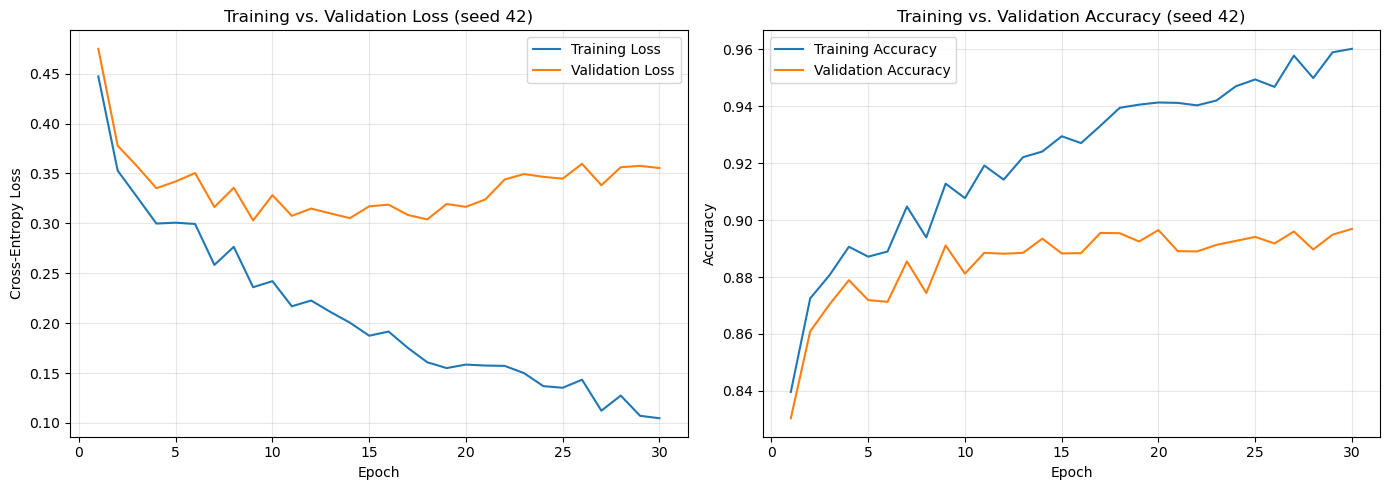

Learning curves saved to: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks\results\figures\baseline_learning_curves.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Training Loss")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation Loss")
axes[0].set_title(f"Training vs. Validation Loss (seed {PRIMARY_SEED})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_df["epoch"], history_df["train_accuracy"], label="Training Accuracy")
axes[1].plot(history_df["epoch"], history_df["val_accuracy"], label="Validation Accuracy")
axes[1].set_title(f"Training vs. Validation Accuracy (seed {PRIMARY_SEED})")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

figure_path = FIGURES_DIR / "baseline_learning_curves.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Learning curves saved to:", figure_path)

## 8. Generalization Gap Analysis

The generalization gap measures the difference between training and validation performance. Both are computed in evaluation mode with the same procedure (Section 7).

A larger training-validation accuracy gap can indicate overfitting. However, the gap should be interpreted alongside the loss curves because accuracy alone does not capture the model's confidence in its predictions. A typical sign of overfitting in the loss curves is a validation loss that stops decreasing (or increases) while the training loss keeps decreasing; the next cell locates that epoch.

We use the final epoch as a descriptive summary, not as proof that the model has reached its optimal generalization performance. The final test accuracy of the baseline model is also computed here (the test set is not used for any decision).

In [9]:
final_metrics = history_df.iloc[-1]

accuracy_gap = final_metrics["train_accuracy"] - final_metrics["val_accuracy"]
loss_gap = final_metrics["val_loss"] - final_metrics["train_loss"]

best_val_loss_row = history_df.loc[history_df["val_loss"].idxmin()]
baseline_test_loss, baseline_test_accuracy = evaluate(model, test_loader)

print(f"Final training accuracy: {final_metrics['train_accuracy']:.4f}")
print(f"Final validation accuracy: {final_metrics['val_accuracy']:.4f}")
print(f"Accuracy gap: {accuracy_gap:.4f}")
print(f"Training loss: {final_metrics['train_loss']:.4f}")
print(f"Validation loss: {final_metrics['val_loss']:.4f}")
print(f"Validation-training loss gap: {loss_gap:.4f}")
print(
    f"\nLowest validation loss: {best_val_loss_row['val_loss']:.4f} "
    f"at epoch {int(best_val_loss_row['epoch'])} "
    f"(training continued for {EPOCHS - int(best_val_loss_row['epoch'])} more epochs)"
)
print(f"\nBaseline test loss: {baseline_test_loss:.4f}")
print(f"Baseline test accuracy: {baseline_test_accuracy:.4f}")

Final training accuracy: 0.9602
Final validation accuracy: 0.8969
Accuracy gap: 0.0633
Training loss: 0.1047
Validation loss: 0.3554
Validation-training loss gap: 0.2507

Lowest validation loss: 0.3030 at epoch 9 (training continued for 21 more epochs)

Baseline test loss: 0.4026
Baseline test accuracy: 0.8906


## 9. Baseline Membership Inference Attack

A Membership Inference Attack (MIA) attempts to determine whether a specific sample was part of a model's training dataset.

In this experiment:

- Members are the samples of the training subset (50,000).
- Non-members are the samples of the official **test set** (10,000). The same non-member set is used for every model in this project.
- The attack score is `logit(true class) - logsumexp(other logits)`, computed in float64. It is a monotone transform of the per-sample cross-entropy loss (`loss = softplus(-score)`), so this is the same loss-based attack, but without the numerical saturation of float32 cross-entropy: for very confident predictions the float32 loss is exactly 0 for many samples, which creates ties and forces the TPR at low FPR to be exactly 0.
- Higher scores indicate a greater likelihood that a sample was used for training.

The attack is evaluated using ROC-AUC (with a bootstrap 95% confidence interval), the true positive rate at 1% and 0.1% false positive rate, and the attack advantage `max(TPR - FPR)`. TPR and FPR are class-conditional rates, so the different sizes of the member and non-member sets do not bias these metrics.

This is a loss-based baseline attack. It is a diagnostic experiment, not a complete evaluation of all possible membership inference attacks.

In [10]:
@torch.no_grad()
def collect_membership_scores(model, loader, device=DEVICE):

    model.eval()
    chunks = []
    for images, labels in loader:
        logits = model(images.to(device)).double()
        labels = labels.to(device)
        true_logit = logits.gather(1, labels[:, None]).squeeze(1)
        other_logits = logits.scatter(1, labels[:, None], float("-inf"))
        chunks.append((true_logit - torch.logsumexp(other_logits, dim=1)).cpu())
    return torch.cat(chunks).numpy()


def scores_to_loss(scores):
    return np.logaddexp(0.0, -scores)


def mia_metrics(member_scores, nonmember_scores, n_boot=200, seed=SEED):
    y_true = np.concatenate([np.ones(len(member_scores)), np.zeros(len(nonmember_scores))])
    y_score = np.concatenate([member_scores, nonmember_scores])

    auc = roc_auc_score(y_true, y_score)
    fpr, tpr, _ = roc_curve(y_true, y_score, drop_intermediate=False)

    def tpr_at(max_fpr):
        return float(tpr[fpr <= max_fpr].max())

    rng = np.random.default_rng(seed)
    boot_aucs = []
    for _ in range(n_boot):
        m = rng.choice(member_scores, size=len(member_scores), replace=True)
        n = rng.choice(nonmember_scores, size=len(nonmember_scores), replace=True)
        boot_aucs.append(
            roc_auc_score(
                np.concatenate([np.ones(len(m)), np.zeros(len(n))]),
                np.concatenate([m, n]),
            )
        )
    ci_low, ci_high = np.percentile(boot_aucs, [2.5, 97.5])

    return {
        "roc_auc": float(auc),
        "auc_ci_low": float(ci_low),
        "auc_ci_high": float(ci_high),
        "tpr_at_fpr_1pct": tpr_at(0.01),
        "tpr_at_fpr_0_1pct": tpr_at(0.001),
        "attack_advantage": float(np.max(tpr - fpr)),
        "tie_fraction": float(1.0 - len(np.unique(y_score)) / len(y_score)),
    }

In [11]:
member_scores = collect_membership_scores(model, train_eval_loader)
nonmember_scores = collect_membership_scores(model, test_loader)

mia = mia_metrics(member_scores, nonmember_scores)
auc_check = mannwhitneyu(member_scores, nonmember_scores).statistic / (
    len(member_scores) * len(nonmember_scores)
)

print("Member dataset: training subset")
print("Non-member dataset: official test set")
print("Member samples:", len(member_scores))
print("Non-member samples:", len(nonmember_scores))
print()
print(f"Membership inference ROC-AUC: {mia['roc_auc']:.4f} "
      f"(95% bootstrap CI: {mia['auc_ci_low']:.4f} - {mia['auc_ci_high']:.4f})")
print(f"ROC-AUC check (Mann-Whitney): {auc_check:.4f}")
print(f"TPR at FPR <= 1%:   {mia['tpr_at_fpr_1pct']:.4f}")
print(f"TPR at FPR <= 0.1%: {mia['tpr_at_fpr_0_1pct']:.4f}")
print(f"Attack advantage max(TPR - FPR): {mia['attack_advantage']:.4f}")
print(f"Fraction of tied scores: {mia['tie_fraction']:.4f}")
print("Random-guess AUC reference: 0.5000")

Member dataset: training subset
Non-member dataset: official test set
Member samples: 50000
Non-member samples: 10000

Membership inference ROC-AUC: 0.5260 (95% bootstrap CI: 0.5194 - 0.5322)
ROC-AUC check (Mann-Whitney): 0.5260
TPR at FPR <= 1%:   0.0095
TPR at FPR <= 0.1%: 0.0014
Attack advantage max(TPR - FPR): 0.0751
Fraction of tied scores: 0.0000
Random-guess AUC reference: 0.5000


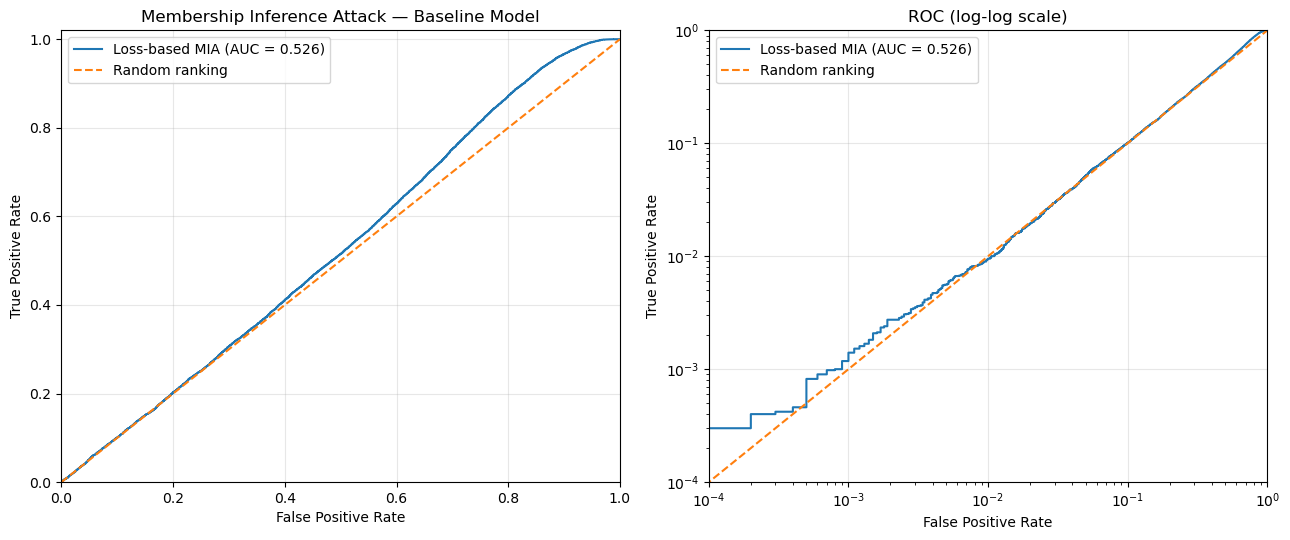

ROC figure saved to: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks\results\figures\baseline_mia_roc.png


In [12]:
fpr, tpr, _ = roc_curve(
    np.concatenate([np.ones(len(member_scores)), np.zeros(len(nonmember_scores))]),
    np.concatenate([member_scores, nonmember_scores]),
    drop_intermediate=False
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, log_scale in zip(axes, [False, True]):
    ax.plot(fpr, tpr, label=f"Loss-based MIA (AUC = {mia['roc_auc']:.3f})")
    ax.plot([1e-5, 1], [1e-5, 1], linestyle="--", label="Random ranking")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.grid(True, alpha=0.3)
    ax.legend()

    if log_scale:
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlim(1e-4, 1)
        ax.set_ylim(1e-4, 1)
        ax.set_title("ROC (log-log scale)")
    else:
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.02)
        ax.set_title("Membership Inference Attack — Baseline Model")

plt.tight_layout()

mia_figure_path = FIGURES_DIR / "baseline_mia_roc.png"
plt.savefig(mia_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("ROC figure saved to:", mia_figure_path)

In [13]:
mia_results = {
    "model": "BaselineMLP",
    "train_seed": PRIMARY_SEED,
    "epochs": EPOCHS,
    "attack": "Loss-based Membership Inference (float64 logit-scaled score)",
    "member_source": "train",
    "nonmember_source": "test",
    "member_count": int(len(member_scores)),
    "nonmember_count": int(len(nonmember_scores)),
    "mean_member_loss": float(scores_to_loss(member_scores).mean()),
    "mean_nonmember_loss": float(scores_to_loss(nonmember_scores).mean()),
    "train_accuracy": float(final_metrics["train_accuracy"]),
    "val_accuracy": float(final_metrics["val_accuracy"]),
    "accuracy_gap": float(accuracy_gap),
    "loss_gap": float(loss_gap),
    "test_loss": float(baseline_test_loss),
    "test_accuracy": float(baseline_test_accuracy),
    **mia,
}

mia_results_path = METRICS_DIR / "baseline_mia_results.json"

with open(mia_results_path, "w", encoding="utf-8") as file:
    json.dump(mia_results, file, indent=4)

print(json.dumps(mia_results, indent=4))
print("\nResults saved to:", mia_results_path)

{
    "model": "BaselineMLP",
    "train_seed": 42,
    "epochs": 30,
    "attack": "Loss-based Membership Inference (float64 logit-scaled score)",
    "member_source": "train",
    "nonmember_source": "test",
    "member_count": 50000,
    "nonmember_count": 10000,
    "mean_member_loss": 0.10474533630886707,
    "mean_nonmember_loss": 0.4026137022719436,
    "train_accuracy": 0.96018,
    "val_accuracy": 0.8969,
    "accuracy_gap": 0.06328,
    "loss_gap": 0.250672579498291,
    "test_loss": 0.4026136962890625,
    "test_accuracy": 0.8906,
    "roc_auc": 0.525995092,
    "auc_ci_low": 0.5194421478000001,
    "auc_ci_high": 0.53216010045,
    "tpr_at_fpr_1pct": 0.00952,
    "tpr_at_fpr_0_1pct": 0.0014,
    "attack_advantage": 0.0751400000000001,
    "tie_fraction": 0.0
}

Results saved to: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks\results\metrics\baseline_mia_results.json


Member score quantiles:
0.00    -9.346679
0.01    -1.769620
0.05     0.209437
0.25     3.772887
0.50     8.203728
0.75    18.135885
0.95    37.385153
0.99    49.425754
1.00    84.473359
dtype: float64

Non-member score quantiles:
0.00   -67.439013
0.01    -7.239683
0.05    -2.202485
0.25     2.853061
0.50     7.857842
0.75    18.038973
0.95    37.135685
0.99    49.781400
1.00    73.215944
dtype: float64


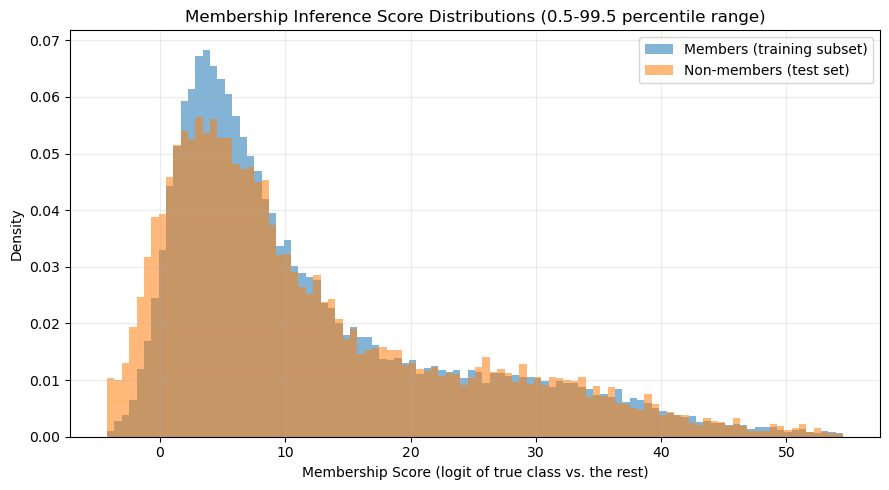

Distribution plot saved to: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks\results\figures\baseline_mia_score_distributions.png


In [14]:
quantiles = [0.00, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1.00]

print("Member score quantiles:")
print(pd.Series(member_scores).quantile(quantiles))

print("\nNon-member score quantiles:")
print(pd.Series(nonmember_scores).quantile(quantiles))

all_scores = np.concatenate([member_scores, nonmember_scores])
low, high = np.percentile(all_scores, [0.5, 99.5])
bins = np.linspace(low, high, 101)

plt.figure(figsize=(9, 5))

plt.hist(member_scores, bins=bins, density=True, alpha=0.55, label="Members (training subset)")
plt.hist(nonmember_scores, bins=bins, density=True, alpha=0.55, label="Non-members (test set)")

plt.xlabel("Membership Score (logit of true class vs. the rest)")
plt.ylabel("Density")
plt.title("Membership Inference Score Distributions (0.5-99.5 percentile range)")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()

distribution_path = FIGURES_DIR / "baseline_mia_score_distributions.png"
plt.savefig(distribution_path, dpi=300, bbox_inches="tight")
plt.show()

print("Distribution plot saved to:", distribution_path)

## 10. Controlled Overfitting Experiment

We investigate whether training duration is associated with changes in generalization and membership inference vulnerability.

All models use the same architecture, training subset, validation subset, optimizer, and learning rate. The primary experimental variable is the number of training epochs: we evaluate the checkpoints saved at epochs 5, 10, 20 and 30 of every training seed (Section 7). For each checkpoint we record the generalization gap and evaluate exactly the same attack as in Section 9.

Checkpoints of one seed come from the same training trajectory, so they are **not independent observations**. We therefore repeat the experiment with several training seeds and report the mean and standard deviation across seeds. Training duration is a proxy for overfitting, not a direct measure of it, so the observed generalization gap is reported alongside the attack performance.

The member and non-member datasets remain fixed across all evaluations. The analysis does not assume that the relationship must be monotonic.

In [15]:
mia_comparison = []

for train_seed in TRAIN_SEEDS:
    seed_history = histories[train_seed].set_index("epoch")

    for epoch in CHECKPOINT_EPOCHS:
        checkpoint = torch.load(
            CHECKPOINT_DIR / f"baseline_seed{train_seed}_epoch{epoch}.pt",
            map_location=DEVICE
        )

        checkpoint_model = BaselineMLP().to(DEVICE)
        checkpoint_model.load_state_dict(checkpoint["model_state_dict"])
        checkpoint_model.eval()

        member_scores_ckpt = collect_membership_scores(checkpoint_model, train_eval_loader)
        nonmember_scores_ckpt = collect_membership_scores(checkpoint_model, test_loader)

        metrics = mia_metrics(member_scores_ckpt, nonmember_scores_ckpt, n_boot=100)
        row = seed_history.loc[epoch]

        mia_comparison.append({
            "seed": train_seed,
            "epoch": epoch,
            "train_accuracy": float(row["train_accuracy"]),
            "val_accuracy": float(row["val_accuracy"]),
            "accuracy_gap": float(row["accuracy_gap"]),
            "train_loss": float(row["train_loss"]),
            "val_loss": float(row["val_loss"]),
            "loss_gap": float(row["loss_gap"]),
            "mean_member_loss": float(scores_to_loss(member_scores_ckpt).mean()),
            "mean_nonmember_loss": float(scores_to_loss(nonmember_scores_ckpt).mean()),
            "mia_roc_auc": metrics["roc_auc"],
            "auc_ci_low": metrics["auc_ci_low"],
            "auc_ci_high": metrics["auc_ci_high"],
            "tpr_at_fpr_1pct": metrics["tpr_at_fpr_1pct"],
            "tpr_at_fpr_0_1pct": metrics["tpr_at_fpr_0_1pct"],
            "attack_advantage": metrics["attack_advantage"],
        })

        print(
            f"Seed {train_seed} | Epoch {epoch:02d} | "
            f"Accuracy Gap: {row['accuracy_gap']:.4f} | "
            f"MIA AUC: {metrics['roc_auc']:.4f} | "
            f"TPR@1% FPR: {metrics['tpr_at_fpr_1pct']:.4f}"
        )

mia_comparison_df = pd.DataFrame(mia_comparison)

comparison_path = METRICS_DIR / "overfitting_vs_mia.csv"
mia_comparison_df.to_csv(comparison_path, index=False)

summary_by_epoch = (
    mia_comparison_df
    .groupby("epoch")[["accuracy_gap", "loss_gap", "mia_roc_auc", "tpr_at_fpr_1pct", "attack_advantage"]]
    .agg(["mean", "std"])
)

print("\nMean and standard deviation across training seeds:")
display(summary_by_epoch.round(4))

print("Results saved to:", comparison_path)

Seed 42 | Epoch 05 | Accuracy Gap: 0.0153 | MIA AUC: 0.5109 | TPR@1% FPR: 0.0103
Seed 42 | Epoch 10 | Accuracy Gap: 0.0265 | MIA AUC: 0.5136 | TPR@1% FPR: 0.0112
Seed 42 | Epoch 20 | Accuracy Gap: 0.0448 | MIA AUC: 0.5210 | TPR@1% FPR: 0.0104
Seed 42 | Epoch 30 | Accuracy Gap: 0.0633 | MIA AUC: 0.5260 | TPR@1% FPR: 0.0095
Seed 43 | Epoch 05 | Accuracy Gap: 0.0116 | MIA AUC: 0.5107 | TPR@1% FPR: 0.0106
Seed 43 | Epoch 10 | Accuracy Gap: 0.0267 | MIA AUC: 0.5133 | TPR@1% FPR: 0.0097
Seed 43 | Epoch 20 | Accuracy Gap: 0.0477 | MIA AUC: 0.5201 | TPR@1% FPR: 0.0104
Seed 43 | Epoch 30 | Accuracy Gap: 0.0635 | MIA AUC: 0.5247 | TPR@1% FPR: 0.0107
Seed 44 | Epoch 05 | Accuracy Gap: 0.0113 | MIA AUC: 0.5106 | TPR@1% FPR: 0.0089
Seed 44 | Epoch 10 | Accuracy Gap: 0.0299 | MIA AUC: 0.5139 | TPR@1% FPR: 0.0091
Seed 44 | Epoch 20 | Accuracy Gap: 0.0489 | MIA AUC: 0.5205 | TPR@1% FPR: 0.0101
Seed 44 | Epoch 30 | Accuracy Gap: 0.0629 | MIA AUC: 0.5277 | TPR@1% FPR: 0.0101

Mean and standard deviation

accuracy_gap         loss_gap         mia_roc_auc          \
              mean     std     mean     std        mean     std   
epoch                                                             
5           0.0127  0.0022   0.0417  0.0004      0.5108  0.0002   
10          0.0277  0.0019   0.0867  0.0027      0.5136  0.0003   
20          0.0471  0.0021   0.1688  0.0094      0.5205  0.0004   
30          0.0632  0.0003   0.2540  0.0105      0.5262  0.0015   

      tpr_at_fpr_1pct         attack_advantage          
                 mean     std             mean     std  
epoch                                                   
5              0.0099  0.0009           0.0267  0.0017  
10             0.0100  0.0011           0.0364  0.0006  
20             0.0103  0.0002           0.0553  0.0029  
30             0.0101  0.0006           0.0740  0.0010

Results saved to: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks\results\metrics\overfitting_vs_mia.csv


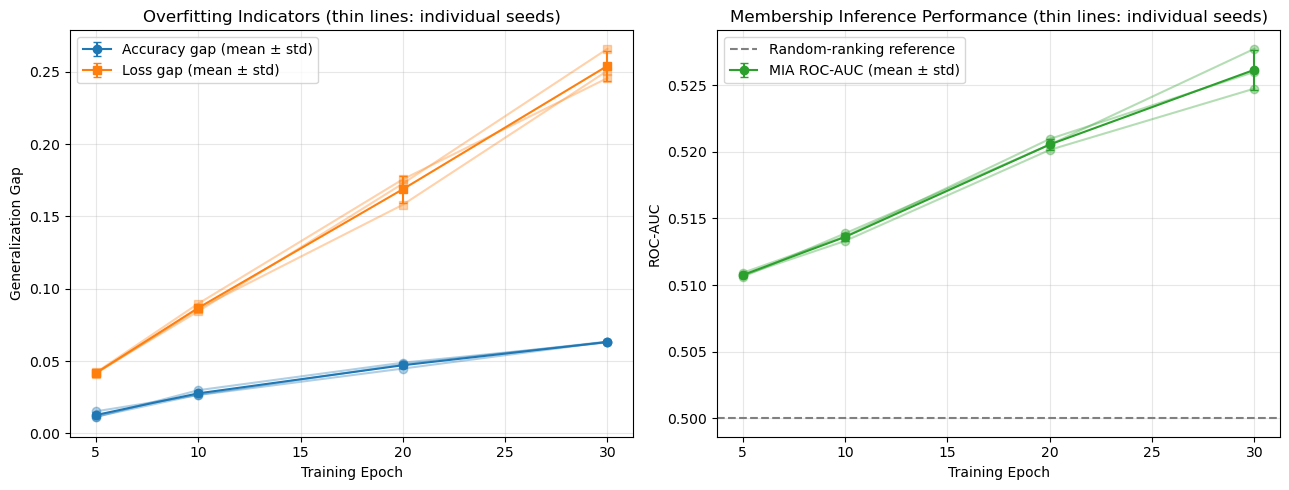

Comparison figure saved to: C:\Users\HADIS\Documents\overfitting-privacy-neural-networks\results\figures\overfitting_vs_mia.png


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for train_seed, group in mia_comparison_df.groupby("seed"):
    axes[0].plot(group["epoch"], group["accuracy_gap"], marker="o", alpha=0.35, color="tab:blue")
    axes[0].plot(group["epoch"], group["loss_gap"], marker="s", alpha=0.35, color="tab:orange")
    axes[1].plot(group["epoch"], group["mia_roc_auc"], marker="o", alpha=0.35, color="tab:green")

mean_by_epoch = mia_comparison_df.groupby("epoch").mean(numeric_only=True)
std_by_epoch = mia_comparison_df.groupby("epoch").std(numeric_only=True)

axes[0].errorbar(
    mean_by_epoch.index, mean_by_epoch["accuracy_gap"], yerr=std_by_epoch["accuracy_gap"],
    marker="o", color="tab:blue", capsize=3, label="Accuracy gap (mean ± std)"
)
axes[0].errorbar(
    mean_by_epoch.index, mean_by_epoch["loss_gap"], yerr=std_by_epoch["loss_gap"],
    marker="s", color="tab:orange", capsize=3, label="Loss gap (mean ± std)"
)
axes[0].set_xlabel("Training Epoch")
axes[0].set_ylabel("Generalization Gap")
axes[0].set_title("Overfitting Indicators (thin lines: individual seeds)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].errorbar(
    mean_by_epoch.index, mean_by_epoch["mia_roc_auc"], yerr=std_by_epoch["mia_roc_auc"],
    marker="o", color="tab:green", capsize=3, label="MIA ROC-AUC (mean ± std)"
)
axes[1].axhline(0.5, linestyle="--", color="gray", label="Random-ranking reference")
axes[1].set_xlabel("Training Epoch")
axes[1].set_ylabel("ROC-AUC")
axes[1].set_title("Membership Inference Performance (thin lines: individual seeds)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

comparison_figure_path = FIGURES_DIR / "overfitting_vs_mia.png"
plt.savefig(comparison_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Comparison figure saved to:", comparison_figure_path)

## 11. Interpretation and Limitations

How to read the results above:

- **Overfitting.** Compare the epoch at which the validation loss is lowest (Section 8) with the final epoch. If the validation loss rises while the training loss keeps falling, and the accuracy and loss gaps grow with the number of epochs (Section 10), the model is increasingly overfitting.
- **Attack strength.** An ROC-AUC close to 0.5, with a bootstrap confidence interval that includes or nearly includes 0.5, means that this attack distinguishes members from non-members only weakly. Read the TPR at low FPR and the attack advantage together with the AUC; do not read a TPR of zero as proof of privacy unless the tie fraction (Section 9) is also close to zero.
- **Relationship.** If the AUC increases with the generalization gap consistently across training seeds, this is evidence of an association between overfitting and membership distinguishability for this model and attack. Because every training duration is a snapshot of the same run, this does not establish causation.

Limitations:

- One architecture, one dataset and one simple loss-based attack; stronger attacks (e.g. shadow-model / LiRA-style attacks) may find more leakage.
- A small number of training seeds and checkpoints; the data split is fixed across seeds.
- Training duration is only a proxy for overfitting. Other ways of changing overfitting (training-set size, regularization) are not studied here.
- The test set is used as the non-member set; no model selection is performed on it.